# 01 — EDA: volume, rótulo, maturação e drift natural por safra

Exploração do Lending Club (empréstimos aceitos). **Só agregados** são exibidos — nenhuma linha individual.
A lógica de carga, alvo, maturação e separação vem de `src/data/`; este notebook não reimplementa nada do pipeline.

Perguntas:
1. Quanto volume há por safra e qual fatia está no escopo (aplicação individual)?
2. Quão imaturo é o rótulo nas safras recentes (censura)?
3. Quais features de originação existem em cada época (nulos estruturais)?
4. Quanto a população já se desloca naturalmente em relação à referência (prévia do PSI)?
5. Qual a qualidade do dado: valores impossíveis, outliers, duplicatas? (insumo das faixas do contrato na F3)
6. Como as features se distribuem, se correlacionam (Pearson × Spearman) e se relacionam com o alvo?
7. Quanto vale, em caixa realizado, aprovar um bom e um mau pagador? (insumo da análise de custo FP/FN)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import get_settings
from src.data.features import CATEGORICAL_FEATURES, add_derived_features, model_feature_columns, numeric_features
from src.data.load import load_dataset
from src.data.target import is_mature, map_target

pd.set_option("display.width", 160, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
settings = get_settings()
raw, snapshot = load_dataset(settings.raw_data_path)
raw["target"] = map_target(raw["loan_status"])
raw["is_mature"] = is_mature(raw["issue_d"], raw["term"], snapshot)
raw["year"] = raw["issue_d"].dt.year
raw = add_derived_features(raw)
print(f"linhas={len(raw):,}  snapshot={snapshot.date()}  safras={raw['issue_d'].min():%Y-%m}..{raw['issue_d'].max():%Y-%m}")

linhas=2,260,668  snapshot=2019-03-01  safras=2007-06..2018-12


## 1. Volume por safra e escopo

In [2]:
vol = pd.crosstab(raw["year"], raw["application_type"], margins=True, margins_name="total")
vol

application_type,Individual,Joint App,total
year,,,
2007,603,0,603
2008,2393,0,2393
2009,5281,0,5281
2010,12537,0,12537
2011,21721,0,21721
2012,53367,0,53367
2013,134814,0,134814
2014,235629,0,235629
2015,420584,511,421095


## 2. Status do rótulo por safra (censura) — aplicações individuais

In [3]:
ind = raw[raw["application_type"] == "Individual"]
status = pd.crosstab(ind["year"], ind["loan_status"], normalize="index").mul(100).round(1)
status[["Fully Paid", "Charged Off", "Current", "Late (31-120 days)", "In Grace Period"]]

loan_status,Fully Paid,Charged Off,Current,Late (31-120 days),In Grace Period
year,,,,,
2007,34.2,7.5,0.0,0.0,0.0
2008,55.0,10.3,0.0,0.0,0.0
2009,78.1,11.2,0.0,0.0,0.0
2010,80.2,11.9,0.0,0.0,0.0
2011,84.8,15.2,0.0,0.0,0.0
2012,83.8,16.2,0.0,0.0,0.0
2013,84.4,15.6,0.0,0.0,0.0
2014,77.2,17.5,5.1,0.1,0.1
2015,71.2,18.0,10.3,0.3,0.1


In [4]:
by_year = ind.groupby("year").agg(
    loans=("target", "size"),
    resolved_share=("target", lambda s: s.notna().mean()),
    mature_share=("is_mature", "mean"),
    bad_rate_resolved=("target", "mean"),
)
by_year["bad_rate_mature"] = ind[ind["is_mature"]].groupby("year")["target"].mean()
by_year.round(4)

,loans,resolved_share,mature_share,bad_rate_resolved,bad_rate_mature
year,,,,,
2007,603,1.0000,1.0000,0.2620,0.2620
2008,2393,1.0000,1.0000,0.2073,0.2073
2009,5281,1.0000,1.0000,0.1369,0.1369
2010,12537,1.0000,1.0000,0.1401,0.1401
2011,21721,1.0000,1.0000,0.1518,0.1518
2012,53367,1.0000,1.0000,0.1620,0.1620
2013,134814,0.9999,1.0000,0.1560,0.1560
2014,235629,0.9468,0.7465,0.1845,0.1463
2015,420584,0.8920,0.6727,0.2018,0.1488


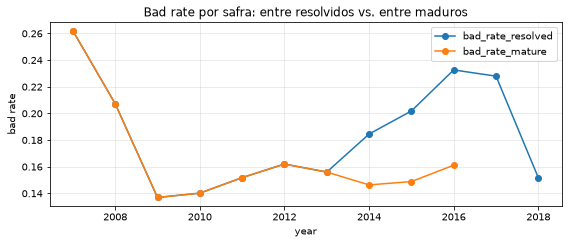

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
by_year[["bad_rate_resolved", "bad_rate_mature"]].plot(ax=ax, marker="o")
ax.set_ylabel("bad rate"); ax.set_title("Bad rate por safra: entre resolvidos vs. entre maduros")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Leitura.** Entre os *resolvidos*, o bad rate das safras recentes é inflado: quem já resolveu um empréstimo jovem é,
desproporcionalmente, quem inadimpliu cedo (quem paga em dia ainda está `Current`). Entre os *maduros* (prazo
integral decorrido até o snapshot) a comparação é justa, mas só existe até ~2016 (36 m) e ~2014 (60 m).
Consequência para o projeto: desempenho com rótulo (L4) em produção natural só é mensurável com atraso — o
*label lag* é real, não só simulado.

## 3. Maturação por prazo

In [6]:
ind.pivot_table(index="year", columns="term", values="is_mature", aggfunc="mean").round(3)

term,36,60
year,,
2007,1.000,NaN
2008,1.000,NaN
2009,1.000,NaN
2010,1.000,1.000
2011,1.000,1.000
2012,1.000,1.000
2013,1.000,1.000
2014,1.000,0.183
2015,1.000,0.000


## 4. Nulos estruturais nas features do modelo

In [7]:
feats = model_feature_columns()
nulls = ind.groupby("year")[feats].apply(lambda g: g.isna().mean()).T.round(2)
nulls[(nulls.loc[:, 2013:] > 0.02).any(axis=1) | (nulls.loc[:, :2012] > 0.5).any(axis=1)]

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
emp_length,0.00,0.00,0.00,0.03,0.03,0.04,0.04,0.05,0.06,0.06,0.06,0.08
mths_since_last_delinq,0.06,0.38,0.67,0.64,0.66,0.59,0.57,0.49,0.48,0.47,0.50,0.55
mort_acc,1.00,1.00,1.00,1.00,1.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00
pub_rec_bankruptcies,0.97,0.33,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
acc_open_past_24mths,1.00,1.00,1.00,1.00,1.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00
bc_util,1.00,1.00,1.00,1.00,1.00,0.15,0.01,0.01,0.01,0.01,0.01,0.01
avg_cur_bal,1.00,1.00,1.00,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00
tot_hi_cred_lim,1.00,1.00,1.00,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00
num_actv_rev_tl,1.00,1.00,1.00,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00
percent_bc_gt_75,1.00,1.00,1.00,1.00,1.00,0.15,0.01,0.01,0.01,0.01,0.01,0.01


Features de bureau (`acc_open_past_24mths`, `bc_util`, `mort_acc`, `tot_*`…) são nulas antes de 2012 e parciais em 2012 —
por isso a referência começa em 2013. `mths_since_last_delinq` e `mths_since_recent_inq` têm nulo *informativo*
(nunca houve o evento).

## 5. Cardinalidade e níveis novos das categóricas

In [8]:
ind.groupby("year")[list(CATEGORICAL_FEATURES) + ["addr_state"]].nunique().T

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
grade,7,7,7,7,7,7,7,7,7,7,7,7
home_ownership,4,5,4,4,4,5,3,4,4,4,5,4
verification_status,1,3,3,3,3,3,3,3,3,3,3,3
purpose,13,14,14,14,13,13,13,13,14,13,14,13
addr_state,38,47,43,44,45,46,49,49,49,50,50,50


In [9]:
ref = ind[ind["year"] == 2013]
rows = []
for col in CATEGORICAL_FEATURES:
    ref_levels = set(ref[col].dropna().unique())
    for year in range(2014, 2019):
        cur = set(ind.loc[ind["year"] == year, col].dropna().unique())
        rows.append({"feature": col, "year": year, "levels": len(cur), "new_vs_2013": sorted(cur - ref_levels)})
pd.DataFrame(rows).pivot(index="feature", columns="year", values="new_vs_2013")

year,2014,2015,2016,2017,2018
feature,,,,,
grade,[],[],[],[],[]
home_ownership,[ANY],[ANY],[ANY],"[ANY, NONE]",[ANY]
purpose,[],[educational],[],[educational],[]
verification_status,[],[],[],[],[]


## 6. Distribuições: referência (2013) × produção

In [10]:
key = ["int_rate", "annual_inc", "dti", "fico_range_low", "loan_amnt", "revol_util", "bc_util"]
q = ind[ind["year"].isin([2013, 2016, 2018])].groupby("year")[key].quantile([0.1, 0.5, 0.9]).unstack(level=1)
q.round(2)

int_rate               annual_inc                      dti               fico_range_low               loan_amnt                   revol_util              \
          0.1    0.5    0.9        0.1      0.5       0.9   0.1    0.5    0.9            0.1    0.5    0.9       0.1      0.5      0.9        0.1   0.5   0.9   
year                                                                                                                                                            
2013     8.90  14.33  20.80    35000.0  64000.0  120000.0  7.32  16.89  27.77          665.0  690.0  730.0    5000.0  13000.0  26000.0       27.5  60.3  87.6   
2016     7.39  11.99  19.99    35000.0  67000.0  131000.0  7.66  18.12  30.32          665.0  690.0  740.0    5000.0  12000.0  28000.0       18.1  50.2  83.9   
2018     6.67  11.80  19.92    35000.0  70000.0  140000.0  6.48  17.04  29.73          665.0  700.0  755.0    5000.0  12600.0  30000.0       11.7  41.8  79.0   

     bc_util              
         0.1   0.5   0.9  
year                      
2013    28.9  72.0  96.3  
2016    17.9  60.6  94.9  
2018    10.8  48.4  90.9

## 7. Prévia do drift natural: PSI anual contra a referência 2013

PSI com bins de **decis da referência** (fixos), ε = 1e-4 em bin vazio, categorias tratadas como bins. Esta é uma
prévia exploratória; a implementação oficial (com testes e cruzamento com Evidently) é da F5.

In [11]:
EPS = 1e-4

def psi(ref_s, cur_s, categorical):
    if categorical:
        r, c = ref_s.value_counts(normalize=True), cur_s.value_counts(normalize=True)
        idx = r.index.union(c.index)
        r, c = r.reindex(idx, fill_value=0), c.reindex(idx, fill_value=0)
    else:
        edges = np.unique(np.nanquantile(ref_s.dropna(), np.linspace(0, 1, 11)))
        edges[0], edges[-1] = -np.inf, np.inf
        r = pd.cut(ref_s.dropna(), edges).value_counts(normalize=True, sort=False)
        c = pd.cut(cur_s.dropna(), edges).value_counts(normalize=True, sort=False)
    r, c = r.clip(lower=EPS), c.clip(lower=EPS)
    return float(((c - r) * np.log(c / r)).sum())

psi_tab = pd.DataFrame({
    year: {f: psi(ref[f], ind.loc[ind["year"] == year, f], f in CATEGORICAL_FEATURES) for f in feats}
    for year in range(2014, 2019)
}).round(3)
psi_tab.sort_values(2018, ascending=False).head(15)

,2014,2015,2016,2017,2018
verification_status,0.244,0.255,0.239,0.291,0.472
percent_bc_gt_75,0.010,0.046,0.120,0.220,0.408
revol_util,0.020,0.051,0.129,0.227,0.401
bc_util,0.009,0.038,0.105,0.207,0.392
int_rate,0.114,0.225,0.255,0.180,0.273
grade,0.029,0.027,0.018,0.054,0.204
inq_last_6mths,0.002,0.044,0.048,0.071,0.112
fico_range_low,0.024,0.020,0.021,0.044,0.112
mort_acc,0.001,0.012,0.035,0.072,0.102
loan_amnt,0.010,0.014,0.029,0.065,0.088


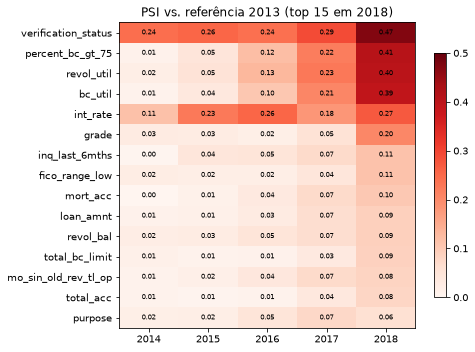

In [12]:
top = psi_tab.sort_values(2018, ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(top.values, cmap="Reds", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(top.shape[1]), top.columns); ax.set_yticks(range(top.shape[0]), top.index)
for i in range(top.shape[0]):
    for j in range(top.shape[1]):
        ax.text(j, i, f"{top.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("PSI vs. referência 2013 (top 15 em 2018)"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

In [13]:
bands = pd.cut(psi_tab.stack(), [-np.inf, 0.10, 0.25, np.inf], labels=["< 0,10", "0,10–0,25", "> 0,25"])
bands.groupby(level=1).value_counts().unstack()

,"< 0,10","0,10–0,25","> 0,25"
2014,31,2,0
2015,31,1,1
2016,28,4,1
2017,28,4,1
2018,24,4,5


## 8. Estatística descritiva — referência (safra 2013, individuais)

In [14]:
num = numeric_features()
desc = ref[num].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["skew"] = ref[num].skew(); desc["kurtosis"] = ref[num].kurtosis()
desc["null_rate"] = ref[num].isna().mean()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,null_rate
loan_amnt,134814.0,14707.41,8098.66,1000.00,2000.00,8500.00,13000.00,20000.00,35000.00,35000.00,0.66,-0.20,0.00
term,134814.0,42.12,10.46,36.00,36.00,36.00,36.00,60.00,60.00,60.00,1.12,-0.74,0.00
int_rate,134814.0,14.53,4.44,6.00,6.03,11.14,14.33,17.56,24.89,26.06,0.24,-0.47,0.00
installment,134814.0,452.39,240.77,4.93,66.55,280.80,404.30,587.34,1204.23,1408.13,0.90,0.76,0.00
emp_length,128852.0,6.22,3.57,0.00,0.00,3.00,7.00,10.00,10.00,10.00,-0.33,-1.37,0.04
annual_inc,134814.0,73228.09,48822.37,6000.00,20000.00,45580.75,64000.00,89000.00,230000.00,6100000.00,18.85,1808.41,0.00
dti,134814.0,17.22,7.60,0.00,2.19,11.47,16.89,22.80,33.71,34.99,0.13,-0.69,0.00
delinq_2yrs,134814.0,0.25,0.73,0.00,0.00,0.00,0.00,0.00,3.00,29.00,5.57,68.04,0.00
fico_range_low,134814.0,695.00,28.76,660.00,660.00,675.00,690.00,710.00,795.00,845.00,1.37,2.45,0.00
inq_last_6mths,134814.0,0.79,1.04,0.00,0.00,0.00,0.00,1.00,4.00,6.00,1.52,2.49,0.00


Assimetria forte nas variáveis monetárias (`annual_inc` skew ≈ 19, `revol_bal` ≈ 28, `avg_cur_bal` ≈ 4,7) e nas
contagens raras (`pub_rec` ≈ 24, `delinq_2yrs` ≈ 5,6, `pub_rec_bankruptcies` ≈ 3,3) — justifica o `log1p` nos valores
monetários da regressão logística (ADR-0006) e o uso de **quantis** (não média ± desvio) para bins de PSI e faixas de
contrato. `int_rate`, `dti`, `revol_util` são aproximadamente simétricas.

## 9. Qualidade do dado: duplicatas, valores impossíveis e incoerências

Regras de plausibilidade candidatas a contrato *hard* na F3. Contagem por safra para ver se o problema é pontual ou
estrutural. A coerência da parcela compara `installment` com a parcela de amortização francesa calculada de
`loan_amnt`, `int_rate` e `term`.

In [15]:
def amortized_installment(df):
    r = df["int_rate"] / 100 / 12
    return df["loan_amnt"] * r / (1 - (1 + r) ** (-df["term"]))

rules = {
    "id duplicado": lambda d: d["id"].duplicated(keep=False),
    "annual_inc <= 0": lambda d: d["annual_inc"] <= 0,
    "annual_inc > 1M": lambda d: d["annual_inc"] > 1_000_000,
    "dti < 0": lambda d: d["dti"] < 0,
    "dti > 100": lambda d: d["dti"] > 100,
    "revol_util > 100": lambda d: d["revol_util"] > 100,
    "bc_util > 100": lambda d: d["bc_util"] > 100,
    "int_rate fora de (0, 40]": lambda d: (d["int_rate"] <= 0) | (d["int_rate"] > 40),
    "loan_amnt fora de [500, 40k]": lambda d: (d["loan_amnt"] < 500) | (d["loan_amnt"] > 40_000),
    "fico fora de [300, 850]": lambda d: (d["fico_range_low"] < 300) | (d["fico_range_low"] > 850),
    "histórico de crédito < 0 meses": lambda d: d["credit_history_months"] < 0,
    "parcela incoerente (> 2%)": lambda d: (d["installment"] / amortized_installment(d) - 1).abs() > 0.02,
    "tot_hi_cred_lim = 9.999.999 (sentinela?)": lambda d: d["tot_hi_cred_lim"] == 9_999_999,
}
flags = pd.DataFrame({name: f(ind) for name, f in rules.items()})
quality = flags.groupby(ind["year"]).sum().T
quality["total"] = quality.sum(axis=1)
quality

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,total
id duplicado,0,0,0,0,0,0,0,0,0,0,0,0,0
annual_inc <= 0,0,0,0,0,0,0,0,0,0,0,0,0,0
annual_inc > 1M,0,1,3,8,3,7,10,27,94,114,104,206,577
dti < 0,0,0,0,0,0,0,0,0,0,1,0,0,1
dti > 100,0,0,0,0,0,0,0,0,0,0,0,0,0
revol_util > 100,9,18,0,0,0,11,245,1009,2210,1550,1212,741,7005
bc_util > 100,0,0,0,0,0,917,2590,4575,8151,6021,4432,2808,29494
"int_rate fora de (0, 40]",0,0,0,0,0,0,0,0,0,0,0,0,0
"loan_amnt fora de [500, 40k]",0,0,0,0,0,0,0,0,0,0,0,0,0
"fico fora de [300, 850]",0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
incoh = (ind["installment"] / amortized_installment(ind) - 1)
print("erro relativo da parcela — quantis:", incoh.quantile([0.5, 0.99, 0.999]).round(4).to_dict())

erro relativo da parcela — quantis: {0.5: 0.0, 0.99: 0.0001, 0.999: 0.0002}


Leitura:
- **Impossíveis de fato** (renda ≤ 0, DTI < 0, juros fora de (0, 40], valor fora de [500, 40k], FICO fora de [300, 850],
  histórico negativo, id duplicado): praticamente zero no dado real — são regras *hard* baratas que protegem contra
  bug de fonte, exatamente o que o gerador de lote ruim da F3 vai injetar.
- **Utilização acima de 100%** (`revol_util`, `bc_util`) acontece aos milhares: cartão estourado é real. Não é erro → aviso
  *soft* ou teto alto, nunca bloqueio em 100.
- **Parcela incoerente** concentra-se em 2008–2011; o erro mediano é zero e o p99,9 é 0,02% → coerência de parcela é
  regra *hard* viável com tolerância de alguns %.
- **`tot_hi_cred_lim = 9.999.999`** tem cara de valor sentinela (placeholder do bureau), não de dado — regra de
  contrato específica na F3.

## 10. Outliers — regra IQR (Q1 − 3·IQR, Q3 + 3·IQR) e extremos, na referência

In [17]:
q1, q3 = ref[num].quantile(0.25), ref[num].quantile(0.75)
iqr = q3 - q1
outl = pd.DataFrame({
    "share_outlier_3iqr": ((ref[num] < q1 - 3 * iqr) | (ref[num] > q3 + 3 * iqr)).mean(),
    "p99": ref[num].quantile(0.99), "p99.9": ref[num].quantile(0.999), "max": ref[num].max(),
})
outl["max/p99.9"] = outl["max"] / outl["p99.9"].replace(0, np.nan)
outl.sort_values("share_outlier_3iqr", ascending=False).round(3).head(15)

,share_outlier_3iqr,p99,p99.9,max,max/p99.9
delinq_2yrs,0.166,3.00,7.000,29.0,4.143
pub_rec,0.119,2.00,4.000,54.0,13.500
pub_rec_bankruptcies,0.106,1.00,2.000,8.0,4.000
revol_bal,0.016,81078.54,231258.318,2568995.0,11.109
total_bc_limit,0.015,92341.76,151718.700,297800.0,1.963
annual_inc,0.012,230000.00,475000.000,6100000.0,12.842
avg_cur_bal,0.011,72474.30,135217.443,958084.0,7.086
inq_last_6mths,0.007,4.00,6.000,6.0,1.000
tot_hi_cred_lim,0.005,717310.53,1243210.297,9999999.0,8.044
tot_cur_bal,0.005,638477.81,1134238.060,4772549.0,4.208


Pela regra 3·IQR, os "outliers" mais frequentes são contagens raras (`delinq_2yrs` 17%, `pub_rec` 12%,
`pub_rec_bankruptcies` 11%) — aqui a regra IQR falha porque Q1 = Q3 = 0, e qualquer evento vira outlier; não é
anomalia. Nas monetárias a cauda é fina (~1–2%) mas longa: `max/p99,9` de 11–13× em `annual_inc` (6,1 M) e
`revol_bal` (2,6 M), e o máximo de `tot_hi_cred_lim` é o sentinela 9.999.999. Tratamento: **não remover** caudas reais
do treino (`log1p` na regressão; XGBoost robusto); no contrato da F3, bloquear só o impossível e o sentinela, e marcar
a cauda extrema como aviso *soft*.

## 11. Histogramas e KDE — referência × produção

Amostra de 20 mil por safra; eixo recortado em p0,5–p99,5 da referência; `annual_inc` em escala log.

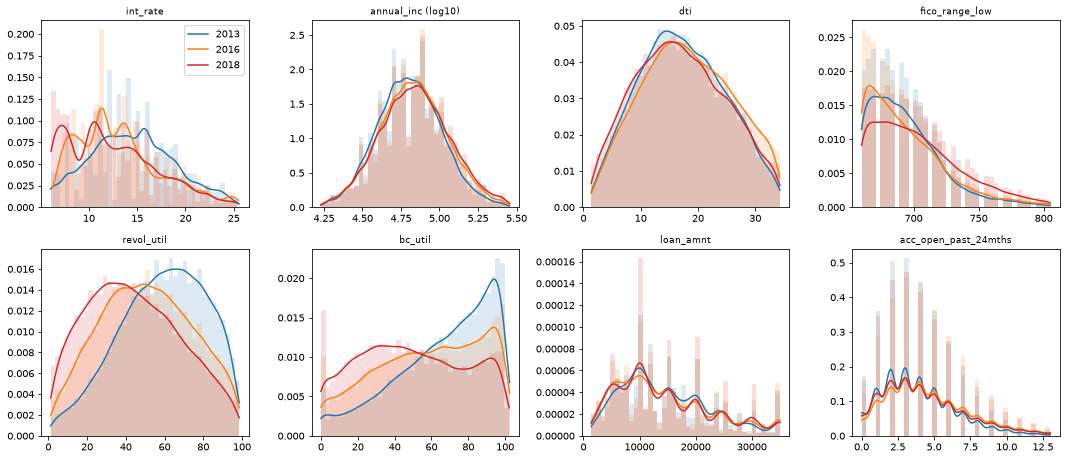

In [18]:
from scipy.stats import gaussian_kde
key_feats = ["int_rate", "annual_inc", "dti", "fico_range_low", "revol_util", "bc_util", "loan_amnt", "acc_open_past_24mths"]
years = [2013, 2016, 2018]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.ravel(), key_feats):
    lo, hi = ref[f].quantile([0.005, 0.995])
    for y, color in zip(years, ["tab:blue", "tab:orange", "tab:red"]):
        s = ind.loc[ind["year"] == y, f].dropna()
        s = s[(s >= lo) & (s <= hi)].sample(min(20_000, len(s)), random_state=0)
        v = np.log10(s.clip(lower=1)) if f == "annual_inc" else s
        ax.hist(v, bins=40, density=True, alpha=0.15, color=color)
        grid = np.linspace(v.min(), v.max(), 200)
        ax.plot(grid, gaussian_kde(v)(grid), color=color, label=str(y))
    ax.set_title(f + (" (log10)" if f == "annual_inc" else ""), fontsize=9)
axes[0, 0].legend(); plt.tight_layout(); plt.show()

Leitura: `int_rate` desloca para a esquerda entre 2013 e 2018 (juros mais baixos); `revol_util` e `bc_util`
caem (tomadores menos alavancados no rotativo); `fico_range_low` sobe levemente; `annual_inc` sobe. É o padrão de
*covariate shift* natural que alimenta o cenário S5 e explica o deslocamento do score no OOT (ADR-0006).

## 12. Relação com o alvo — bad rate por decil e Information Value (referência madura)

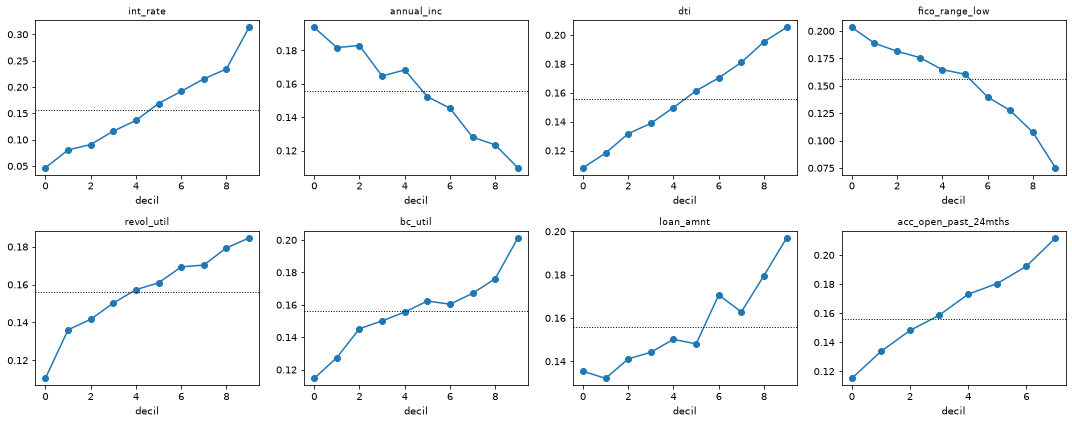

In [19]:
lab = ref[ref["target"].notna()]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.ravel(), key_feats):
    dec = pd.qcut(lab[f], 10, duplicates="drop")
    br = lab.groupby(dec, observed=True)["target"].mean()
    ax.plot(range(len(br)), br.values, marker="o"); ax.set_title(f, fontsize=9)
    ax.axhline(lab["target"].mean(), color="k", ls=":", lw=1); ax.set_xlabel("decil")
plt.tight_layout(); plt.show()

In [20]:
def information_value(x, y, categorical):
    bins = x.astype("string").fillna("NA") if categorical else pd.qcut(x, 10, duplicates="drop").astype("string").fillna("NA")
    t = pd.crosstab(bins, y)
    good, bad = (t[0] + 0.5) / t[0].sum(), (t[1] + 0.5) / t[1].sum()
    return float(((good - bad) * np.log(good / bad)).sum())

iv = pd.Series({f: information_value(lab[f], lab["target"].astype(int), f in CATEGORICAL_FEATURES)
                for f in model_feature_columns()}).sort_values(ascending=False)
iv_band = pd.cut(iv, [-np.inf, 0.02, 0.1, 0.3, np.inf], labels=["inútil", "fraco", "médio", "forte"])
pd.DataFrame({"IV": iv.round(4), "faixa": iv_band}).head(20)

,IV,faixa
int_rate,0.3786,forte
grade,0.3624,forte
fico_range_low,0.0958,fraco
dti,0.0555,fraco
acc_open_past_24mths,0.0480,fraco
annual_inc,0.0435,fraco
avg_cur_bal,0.0366,fraco
verification_status,0.0348,fraco
percent_bc_gt_75,0.0337,fraco
tot_hi_cred_lim,0.0333,fraco


In [21]:
pd.concat({c: lab.groupby(c)["target"].agg(["size", "mean"]).round(4) for c in CATEGORICAL_FEATURES})

size    mean
grade               A                   17679  0.0470
                    B                   44115  0.1017
                    C                   38130  0.1752
                    D                   20566  0.2237
                    E                    9059  0.2850
                    F                    4392  0.3484
                    G                     863  0.3615
home_ownership      MORTGAGE            72061  0.1413
                    OWN                 11248  0.1575
                    RENT                51495  0.1762
verification_status Not Verified        38959  0.1197
                    Source Verified     29707  0.1603
                    Verified            66138  0.1754
purpose             car                  1050  0.1171
                    credit_card         32804  0.1320
                    debt_consolidation  80634  0.1636
                    home_improvement     7403  0.1418
                    house                 675  0.1363
                    major_purchase       2298  0.1292
                    medical               889  0.1789
                    moving                639  0.1706
                    other                5842  0.1943
                    renewable_energy       51  0.1176
                    small_business       1359  0.2575
                    vacation              565  0.1558
                    wedding               595  0.1529

## 13. Correlações — Pearson × Spearman

Pearson mede relação **linear** e é sensível a caudas; Spearman mede relação **monotônica** por postos. Divergência
grande entre os dois indica não linearidade ou influência de outliers.

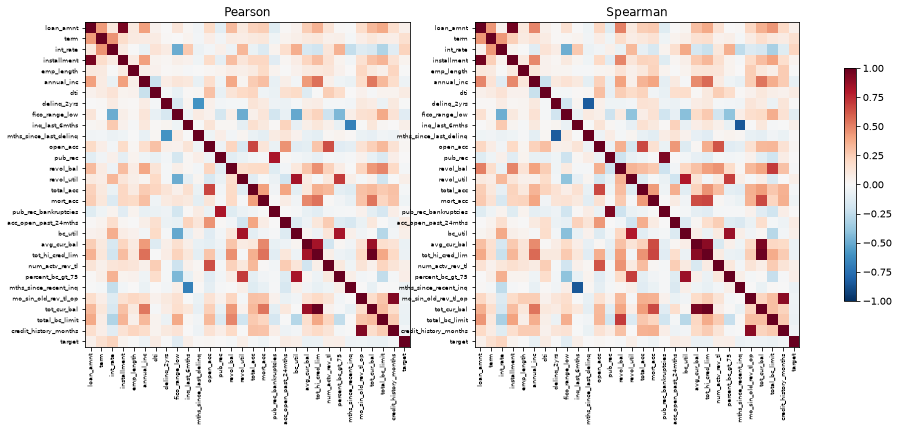

In [22]:
sample = lab[num + ["target"]].sample(40_000, random_state=0)
pear, spear = sample.corr(method="pearson"), sample.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, m) in zip(axes, [("Pearson", pear), ("Spearman", spear)]):
    im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=90, fontsize=6); ax.set_yticks(range(len(m)), m.index, fontsize=6)
    ax.set_title(name)
fig.colorbar(im, ax=axes, shrink=0.6); plt.show()

In [23]:
tri = spear.where(np.triu(np.ones(spear.shape, dtype=bool), k=1)).stack()
pairs = pd.DataFrame({"spearman": tri, "pearson": pear.where(np.triu(np.ones(pear.shape, dtype=bool), k=1)).stack()})
pairs[pairs["spearman"].abs() > 0.7].sort_values("spearman", key=abs, ascending=False).round(3)

,,spearman,pearson
tot_hi_cred_lim,tot_cur_bal,0.979,0.988
loan_amnt,installment,0.965,0.952
avg_cur_bal,tot_cur_bal,0.940,0.858
pub_rec,pub_rec_bankruptcies,0.936,0.817
avg_cur_bal,tot_hi_cred_lim,0.905,0.833
mo_sin_old_rev_tl_op,credit_history_months,0.902,0.924
bc_util,percent_bc_gt_75,0.855,0.827
inq_last_6mths,mths_since_recent_inq,-0.846,-0.675
delinq_2yrs,mths_since_last_delinq,-0.829,-0.596
revol_util,bc_util,0.804,0.830


In [24]:
target_corr = pd.DataFrame({"pearson (ponto-bisserial)": pear["target"], "spearman": spear["target"]}).drop("target")
target_corr["|dif|"] = (target_corr.iloc[:, 0] - target_corr.iloc[:, 1]).abs()
target_corr.sort_values("spearman", key=abs, ascending=False).round(4).head(15)

,pearson (ponto-bisserial),spearman,|dif|
int_rate,0.2201,0.2159,0.0042
term,0.1571,0.1571,0.0000
fico_range_low,-0.1099,-0.1085,0.0014
acc_open_past_24mths,0.0833,0.0839,0.0006
dti,0.0782,0.0792,0.0010
annual_inc,-0.0537,-0.0723,0.0185
percent_bc_gt_75,0.0646,0.0643,0.0003
tot_hi_cred_lim,-0.0621,-0.0618,0.0004
total_bc_limit,-0.0656,-0.0615,0.0041
bc_util,0.0591,0.0606,0.0015


Leitura:
- **Redundâncias** (|ρ Spearman| > 0,9): `tot_hi_cred_lim` × `tot_cur_bal` (0,98), `loan_amnt` × `installment` (0,97),
  `avg_cur_bal` × `tot_cur_bal` (0,94), `pub_rec` × `pub_rec_bankruptcies` (0,94), `mo_sin_old_rev_tl_op` ×
  `credit_history_months` (0,90). A regressão logística convive (coeficientes compartilhados, importância por permutação
  distribuída); ficam como candidatas a poda se a explicabilidade do scorecard exigir.
- **Pearson × Spearman divergem** onde há não linearidade ou cauda: `delinq_2yrs` × `mths_since_last_delinq`
  (−0,83 × −0,60), `inq_last_6mths` × `mths_since_recent_inq` (−0,85 × −0,68), `revol_bal` × `total_bc_limit`
  (0,70 × 0,49) — relações monotônicas, não lineares.
- **Com o alvo**, nenhuma feature passa de |ρ| = 0,22 (`int_rate`); depois `term` (0,16) e `fico_range_low` (−0,11).
  Pearson ≈ Spearman para o alvo (dif. ≤ 0,02), exceto `annual_inc` (−0,054 × −0,072, efeito da cauda). O risco é
  multivariado — coerente com AUC ≈ 0,70 e com o IV: só `int_rate` (0,38) e `grade` (0,36) são fortes.

## 14. Padrões temporais mensais (individuais, 2012–2018)

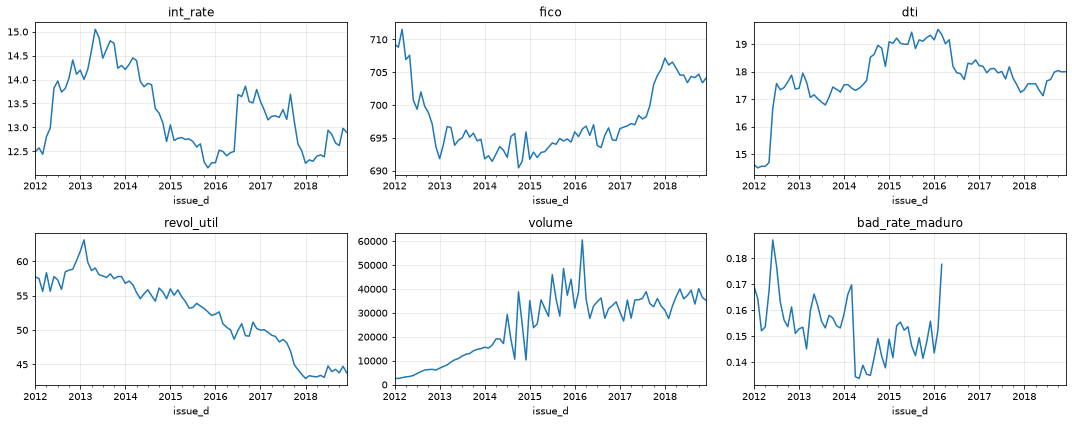

In [25]:
monthly = ind[ind["year"] >= 2012].groupby(ind["issue_d"].dt.to_period("M")).agg(
    int_rate=("int_rate", "mean"), fico=("fico_range_low", "mean"), dti=("dti", "mean"),
    revol_util=("revol_util", "mean"), volume=("int_rate", "size"))
mature = ind[ind["is_mature"] & ind["target"].notna()]
monthly["bad_rate_maduro"] = mature.groupby(mature["issue_d"].dt.to_period("M"))["target"].mean()
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, c in zip(axes.ravel(), monthly.columns):
    monthly[c].plot(ax=ax, title=c); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Volume anual cresce ~8× entre 2012 (53 mil) e 2016 (426 mil). A taxa de juros cai entre 2013 e 2018 (mediana
14,3% → 11,8%, seção 6) enquanto o bad rate maduro anual fica entre 14,6% e 16,1% (seção 2) — o descompasso que gera
a perda de calibração fora do tempo (model card). O bad rate maduro só existe até ~2016.

## 15. Economia realizada — o que aprovar um bom e um mau pagador rende de fato

Colunas de pagamento (`use: custo` no inventário) lidas por `src/models/economics.py` **somente para agregados**.
Caixa líquido = `total_pymnt` − `funded_amnt` − `collection_recovery_fee`. Referência 2013 madura.

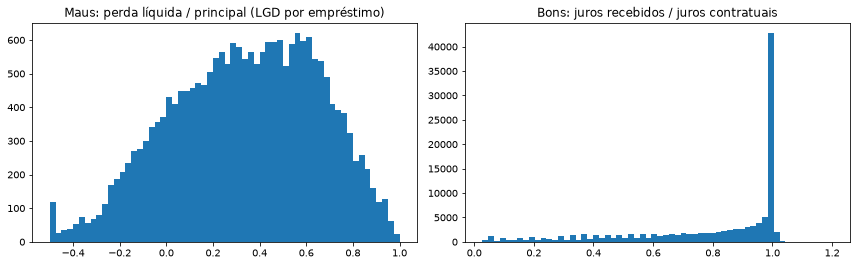

LGD ponderada por valor: 0.327 · realização de juros ponderada: 0.757
maus com caixa líquido positivo (deram lucro apesar do default): 16.0% · maus com perda > 90% do principal: 1.6%


In [26]:
from src.models.economics import read_cost_frame, realized_economics
econ = realized_economics(read_cost_frame(settings.raw_data_path, settings.pseudonymization_key.get_secret_value()))
from src.data.pseudonymize import pseudonymize_ids
ref_keys = pseudonymize_ids(lab["id"], settings.pseudonymization_key.get_secret_value())
econ_ref = econ[econ["loan_key"].isin(set(ref_keys))].copy()
econ_ref["grade"] = econ_ref["loan_key"].map(dict(zip(ref_keys, lab["grade"])))
bad, good = econ_ref[econ_ref["target"] == 1], econ_ref[econ_ref["target"] == 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(bad["loss_rate"].clip(-0.5, 1.2), bins=60); axes[0].set_title("Maus: perda líquida / principal (LGD por empréstimo)")
axes[1].hist(good["interest_realization"].clip(0, 1.2), bins=60); axes[1].set_title("Bons: juros recebidos / juros contratuais")
plt.tight_layout(); plt.show()
print(f"LGD ponderada por valor: {-bad['net_cash'].sum() / bad['funded_amnt'].sum():.3f} · "
      f"realização de juros ponderada: {good['total_rec_int'].sum() / good['contractual_interest'].sum():.3f}")
print(f"maus com caixa líquido positivo (deram lucro apesar do default): {(bad['net_cash'] > 0).mean():.1%} · "
      f"maus com perda > 90% do principal: {(bad['loss_rate'] > 0.9).mean():.1%}")

In [27]:
by_grade = econ_ref.groupby(["grade", "target"]).agg(n=("net_cash", "size"), caixa_medio=("net_cash", "mean"),
    perda_media=("loss_rate", "mean"), realizacao_juros=("interest_realization", "median")).round(3)
by_grade

n  caixa_medio  perda_media  realizacao_juros
grade target                                                   
A     0.0     16848     1655.575       -0.106             0.960
      1.0       831    -5469.512        0.356             0.751
B     0.0     39627     2304.363       -0.166             0.946
      1.0      4488    -4714.615        0.350             0.703
C     0.0     31449     3901.773       -0.248             0.910
      1.0      6681    -4972.990        0.336             0.636
D     0.0     15966     4183.511       -0.286             0.906
      1.0      4600    -4950.538        0.343             0.593
E     0.0      6477     7115.404       -0.381             0.838
      1.0      2582    -5729.596        0.318             0.523
F     0.0      2862     8622.165       -0.445             0.736
      1.0      1530    -6092.172        0.319             0.455
G     0.0       551    10821.340       -0.482             0.644
      1.0       312    -7090.281        0.307             0.452

Leitura: um mau pagador perde, ponderado por valor, ~1/3 do principal (0,327 — não 0,60 como a premissa inicial do
ADR-0007), porque paga parcelas antes do default e há recuperação; a perda média é estável entre grades (0,31–0,36).
A distribuição é larga: uma parcela dos "maus" chega a dar lucro (default tardio, após muitos juros pagos — o acúmulo
em −0,5 no gráfico é o recorte do eixo), o que o rótulo binário não enxerga.
Um bom pagador realiza ~3/4 dos juros contratuais (0,757, por pré-pagamento), menos nas grades piores (0,64 em G).
O caixa médio de um bom cresce com a grade (US$ 1,7 mil em A → US$ 10,8 mil em G) mais rápido que a perda de um mau
(US$ 5,5 mil → 7,1 mil). Essa é a base empírica da validação FP/FN de custo (`make cost`, ADR-0016).

## Conclusões (insumo dos ADRs 0003–0005, 0016, do data card e da F3)

- O eixo temporal é real e longo (2007–2018), mas só a partir de 2013 as features de bureau estão completas → **referência = safra 2013**.
- O rótulo das safras ≥ 2016 é fortemente censurado; bad rate entre resolvidos superestima o risco → **maturação por prazo** define o que é rótulo confiável.
- Já existe **drift natural** relevante entre 2013 e 2018 (PSI, histogramas/KDE): juros e utilização do rotativo caem, FICO e renda sobem.
- **Qualidade:** sem duplicatas e sem valores impossíveis no dado real; utilização > 100% é real (aviso *soft*); parcela incoerente é rara fora de 2008–2011; **`tot_hi_cred_lim` = 9.999.999 é sentinela** → regras da F3.
- **Estatística:** monetárias e contagens raras muito assimétricas (log/quantis; regra IQR inadequada para contagens); só `int_rate` e `grade` têm IV forte; nenhuma |ρ| com o alvo passa de 0,22 → risco multivariado; redundâncias e relações não lineares confirmadas por Pearson × Spearman.
- **Economia:** perda líquida de um mau ≈ 1/3 do principal e realização de juros de um bom ≈ 3/4 — as premissas de custo propostas eram pessimistas.
- Categorias novas aparecem na produção (seção 5) → contrato *soft* da F3.